[*********************100%***********************]  1 of 1 completed

正在下载 AAPL 股票数据...
有效价格数据个数：1002

收益率描述统计：
count   1001.000000
mean       0.000876
std        0.017224
min       -0.092456
25%       -0.007488
50%        0.001187
75%        0.009065
max        0.153289
Name: Return, dtype: float64

损失率描述统计：
count   1001.000000
mean      -0.000876
std        0.017224
min       -0.153289
25%       -0.009065
50%       -0.001187
75%        0.007488
max        0.092456
Name: Loss, dtype: float64

================ POT 阈值信息 ================
样本总数 n       = 1001
阈值分位数       = 90.00%
阈值 u           = 0.017653
超阈值个数 Nu    = 100
超阈值比例 Nu/n  = 9.9900%

================ GPD 参数估计 ================
xi_hat   = 0.047876
beta_hat = 0.011923

================ EVT-GPD 风险估计 ================
AAPL 95% VaR（日损失率） = 0.026044
AAPL 95% ES （日损失率） = 0.038988

换成百分比：
95% VaR = 2.6044%
95% ES  = 3.8988%

================ 历史模拟法作为比较 ================
Historical VaR 95% = 2.6236%
Historical ES  95% = 3.9105%


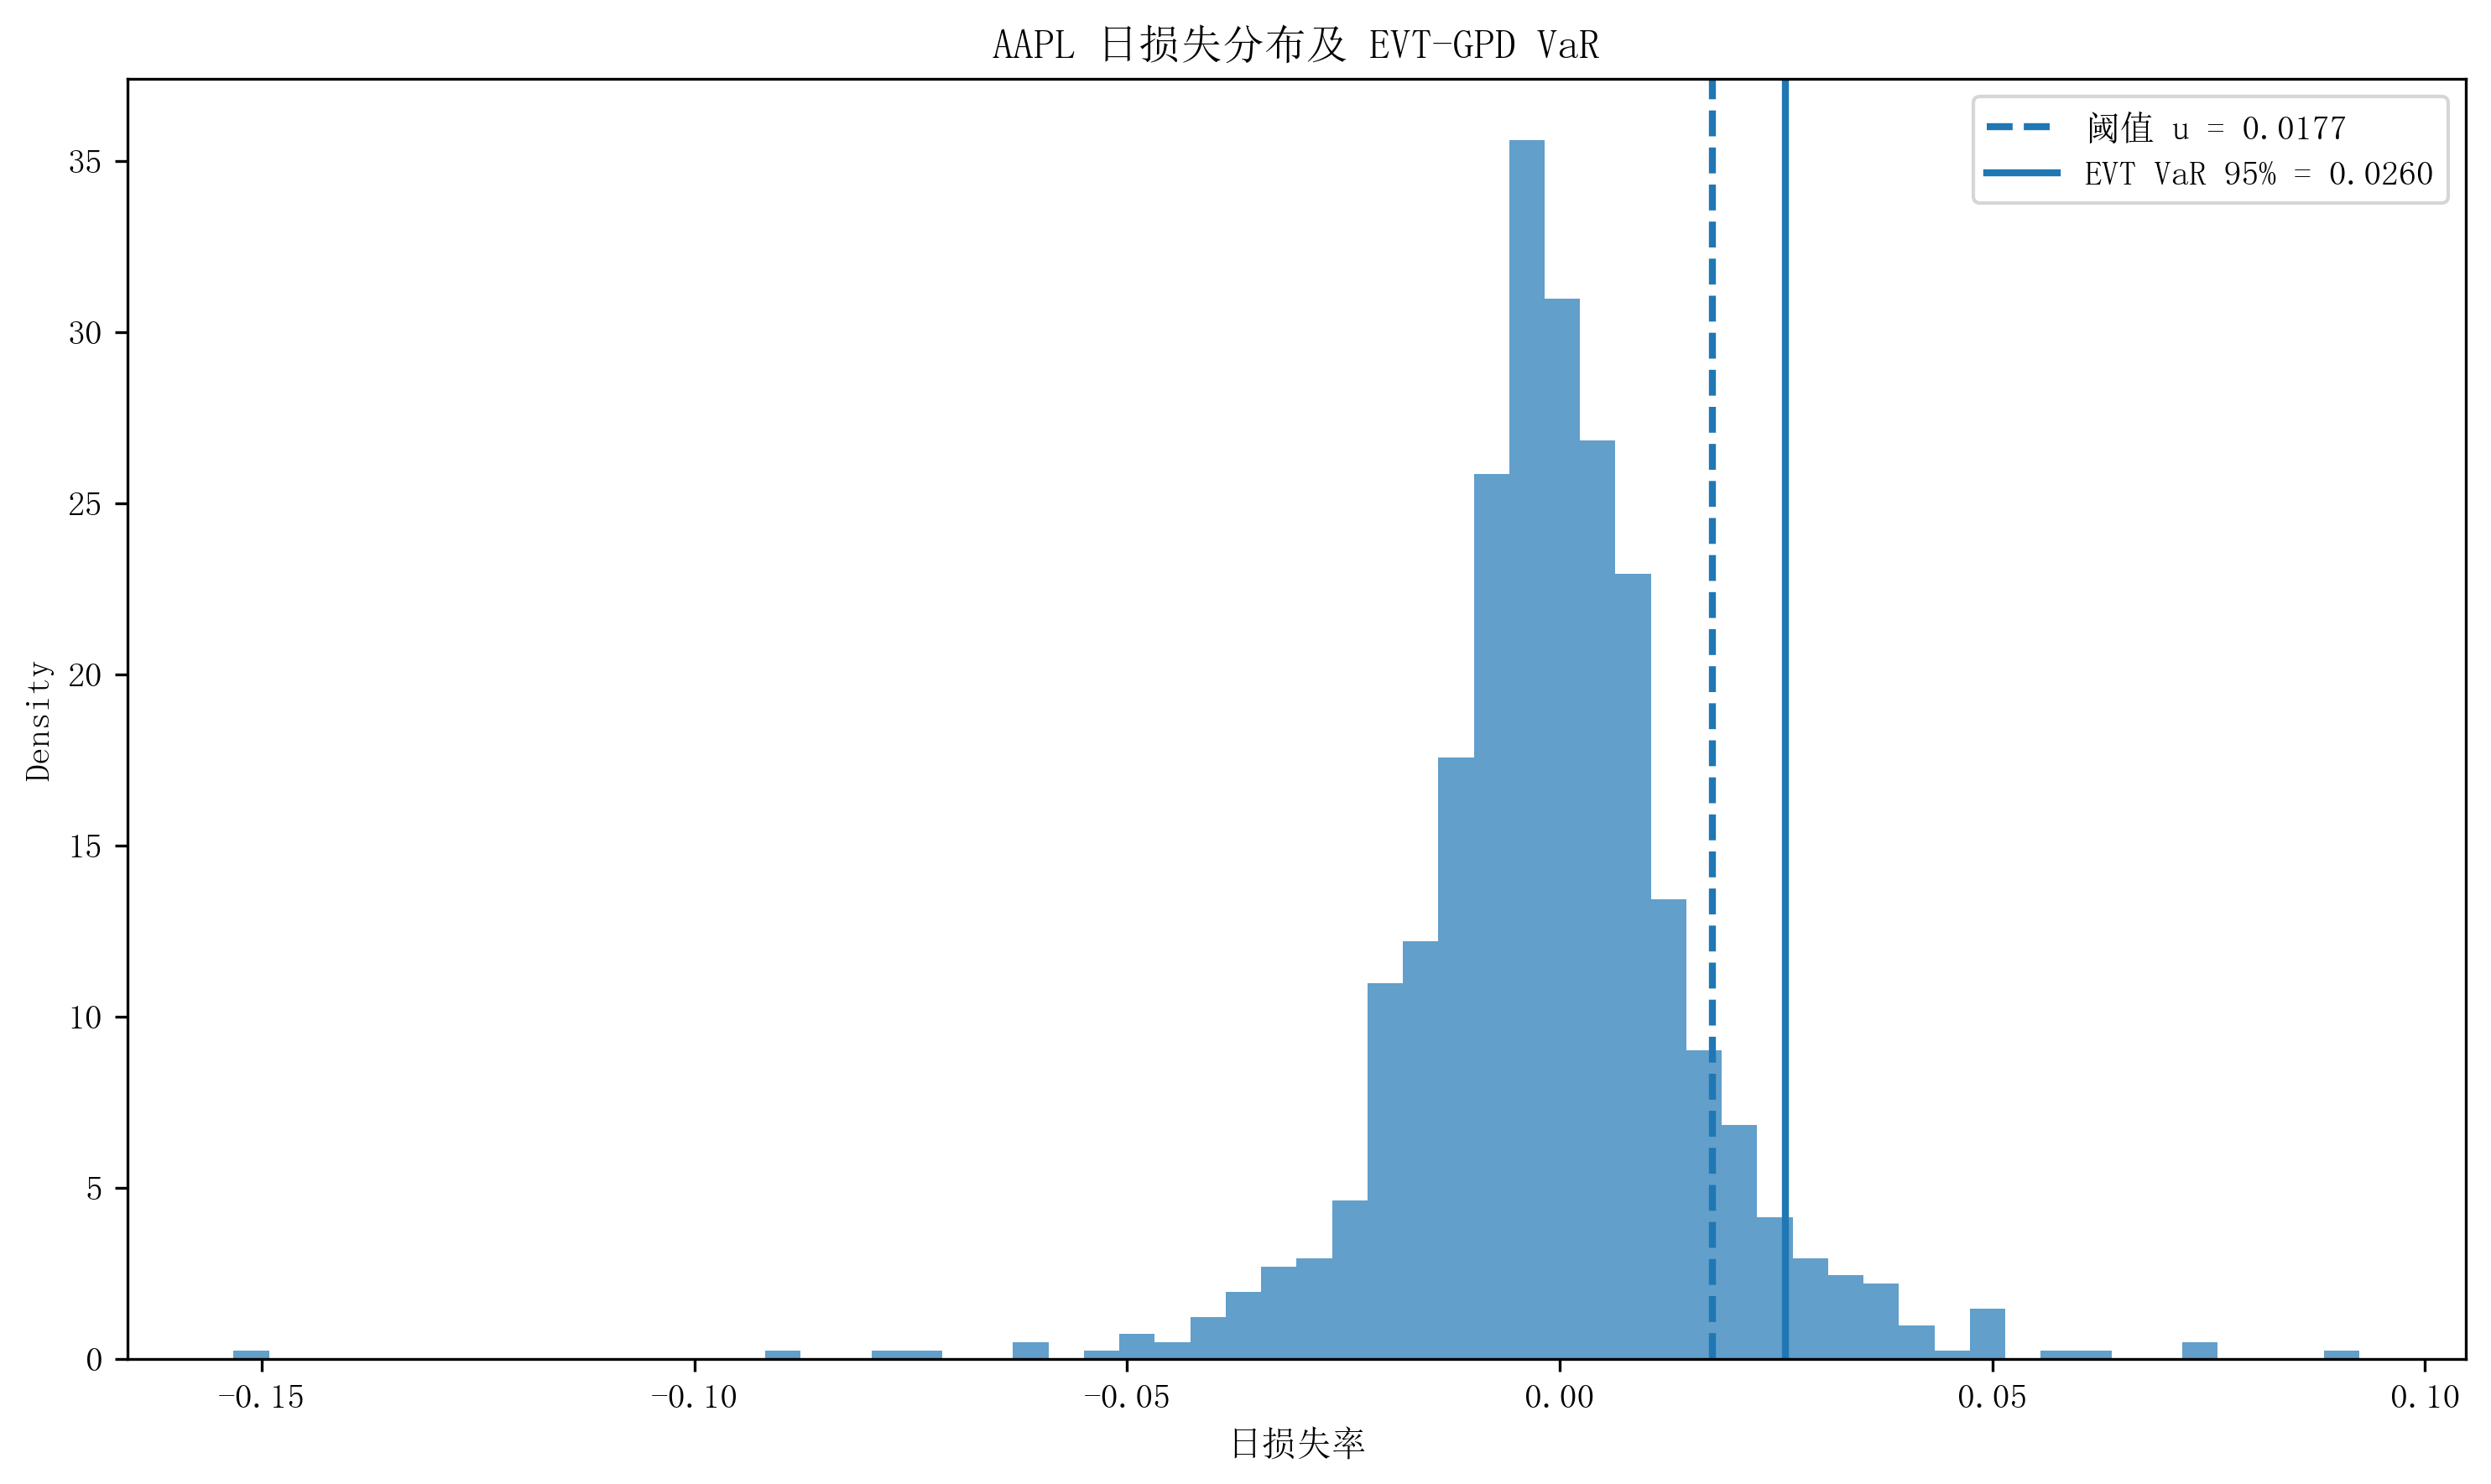

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf

from scipy.stats import genpareto

# ============================================================
# 0. 基本设置
# ============================================================
pd.set_option("display.max_columns", 15)
pd.set_option("display.width", 1000)
pd.set_option("display.float_format", lambda x: "%.6f" % x)

plt.rcParams["font.sans-serif"] = ["SimSun"]
plt.rcParams["axes.unicode_minus"] = False


# ============================================================
# 1. 下载一只股票数据
# ============================================================
ticker = "AAPL"

print(f"正在下载 {ticker} 股票数据...")

raw_data = yf.download(
    ticker,
    start="2022-08-31",
    end="2026-08-31",
    auto_adjust=True
)

# 兼容不同版本 yfinance 返回格式
if isinstance(raw_data.columns, pd.MultiIndex):
    close = raw_data["Close"][ticker].dropna()
else:
    close = raw_data["Close"].dropna()

print(f"有效价格数据个数：{len(close)}")


# ============================================================
# 2. 计算日简单收益率
# ============================================================
ret = close.pct_change().dropna()
ret.name = "Return"

# 为了使用第二题的“右尾 GPD”方法，
# 将负收益转换为正的损失率
loss = -ret
loss.name = "Loss"

print("\n收益率描述统计：")
print(ret.describe())

print("\n损失率描述统计：")
print(loss.describe())


# ============================================================
# 3. 选择 POT 阈值 u
# ============================================================
# 因为目标是估计 95% VaR，
# 阈值需要低于 95% 分位，这里选择经验 90% 分位数
threshold_quantile = 0.90
u = loss.quantile(threshold_quantile)

# 超过阈值的数据
tail_loss = loss[loss > u]

# GPD 所拟合的是超额 Y = L - u
excess = tail_loss - u

n = len(loss)
Nu = len(excess)

print("\n================ POT 阈值信息 ================")
print(f"样本总数 n       = {n}")
print(f"阈值分位数       = {threshold_quantile:.2%}")
print(f"阈值 u           = {u:.6f}")
print(f"超阈值个数 Nu    = {Nu}")
print(f"超阈值比例 Nu/n  = {Nu/n:.4%}")


# ============================================================
# 4. 用极大似然估计 GPD 参数
# ============================================================
# scipy 返回 shape, loc, scale
# shape = xi
# 固定 loc = 0，因为 excess 已经是超过 u 后的超额
xi_hat, loc_hat, beta_hat = genpareto.fit(excess, floc=0)

print("\n================ GPD 参数估计 ================")
print(f"xi_hat   = {xi_hat:.6f}")
print(f"beta_hat = {beta_hat:.6f}")


# ============================================================
# 5. 计算 EVT-GPD VaR_0.95
# ============================================================
q = 0.95

if abs(xi_hat) > 1e-8:

    VaR_95 = (
        u
        + beta_hat / xi_hat
        * (
            ((n / Nu) * (1 - q)) ** (-xi_hat)
            - 1
        )
    )

else:
    # xi -> 0 时 GPD 退化为指数分布
    VaR_95 = (
        u
        + beta_hat
        * np.log(
            Nu / (n * (1 - q))
        )
    )


# ============================================================
# 6. 计算 EVT-GPD ES_0.95
# ============================================================
if xi_hat < 1:

    ES_95 = (
        VaR_95
        + beta_hat
        - xi_hat * u
    ) / (1 - xi_hat)

else:
    ES_95 = np.inf


# ============================================================
# 7. 输出结果
# ============================================================
print("\n================ EVT-GPD 风险估计 ================")

print(f"{ticker} 95% VaR（日损失率） = {VaR_95:.6f}")
print(f"{ticker} 95% ES （日损失率） = {ES_95:.6f}")

print(f"\n换成百分比：")
print(f"95% VaR = {VaR_95 * 100:.4f}%")
print(f"95% ES  = {ES_95 * 100:.4f}%")


# ============================================================
# 8. 与历史模拟 VaR / ES 比较
# ============================================================
VaR_hist = loss.quantile(q)

ES_hist = loss[loss > VaR_hist].mean()

print("\n================ 历史模拟法作为比较 ================")

print(f"Historical VaR 95% = {VaR_hist * 100:.4f}%")
print(f"Historical ES  95% = {ES_hist * 100:.4f}%")


# ============================================================
# 9. 绘制损失分布与阈值
# ============================================================
plt.figure(figsize=(10, 6), dpi=300)

plt.hist(
    loss,
    bins=60,
    density=True,
    alpha=0.7
)

plt.axvline(
    u,
    linestyle="--",
    linewidth=2,
    label=f"阈值 u = {u:.4f}"
)

plt.axvline(
    VaR_95,
    linestyle="-",
    linewidth=2,
    label=f"EVT VaR 95% = {VaR_95:.4f}"
)

plt.xlabel("日损失率")
plt.ylabel("Density")
plt.title(f"{ticker} 日损失分布及 EVT-GPD VaR")
plt.legend()

plt.tight_layout()
plt.show()